## Figure 2. Feature selection and coefficients underlying the NMWI. 
Feature selection and coefficients underlying the NMWI. **(a)** LASSO-penalized logistic regression coefficients: 14 taxa with positive coefficients, 10 with negative coefficients, and 160 with coefficients shrunk to zero. Bubble size indicates selection frequency across LOSO CV, and color indicates coefficient magnitude. **(b)** Heatmap of coefficients across LOSO CV models, in which each column represents a model trained with one study held out; and each row represents a taxon in the final model. Coefficients are represented using the same color scale as in panel **(a)**.


In [1]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
import glob, warnings, sys, runpy
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, LeaveOneGroupOut, GridSearchCV, RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", message="pkg_resources is deprecated as an API")


In [ ]:
# Run only once to get the working directory
project_root = Path("../../").resolve()
os.chdir(project_root)
print("Working dir:", Path.cwd())

In [2]:
%matplotlib inline
# METADATA LOADING
vars_dict = runpy.run_path("Codes/Auxiliary_files/Generate_data_index.py")
globals().update(vars_dict)
X_new = X.copy()

Found 27 genus tables in index
Number of samples: 1654, and number of taxa: 184
Number of unique studies: 27

Sample ID per Category:
Category  n_Sample ID
    case         1065
 control          589


- X: DataFrame (rows=samples, cols=taxonomy), index includes bioproject/sample_id RELATIVE ABUNDANCE
- y: Series/array-like of True/False (same index as X), True (1) =control, False=case

## Hyperparameters search 
Hyperparameter optimization of the L1-regularized logistic regression model. Leave-one-study-out cross-validation (LOSO CV) performance across a grid of regularization parameter values (C). The x-axis shows C (inverse regularization strength), and the y-axis shows mean balanced accuracy within LOSO CV. The optimal C was selected as the value yielding the highest mean balanced accuracy.

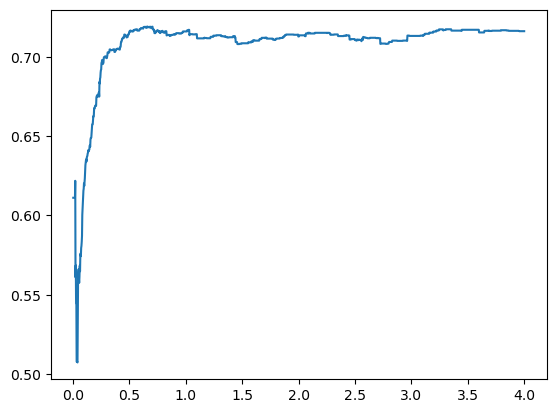

In [3]:
# --------------------------------------------------
# LOSO GRID SEARCH FOR BEST C 
# (Takes a while to run)
# --------------------------------------------------

# Base parameters shared by all models
model_params = dict(
    random_state=42,
    penalty="l1",
    solver="liblinear",
    class_weight="balanced",
    max_iter=2000
)

# Grid search for parameters
C_grid = np.arange(0.0025, 4.0025, 0.0025)

# Groups for LOSO
bio_ids = np.array(X_new.index.get_level_values(0))
loso = LeaveOneGroupOut()

X_arr = X_new
y_arr = y.values.ravel()

loso_results = []
loso_scores = np.full(len(y), np.nan)

for C_val in C_grid:
    fold_bas = []

    for train_idx, test_idx in loso.split(X_arr, y_arr, groups=bio_ids):
        X_tr = X_arr.iloc[train_idx]
        X_te = X_arr.iloc[test_idx]
        y_tr = y_arr[train_idx]
        y_te = y_arr[test_idx]

        model = LogisticRegression(**model_params, C=C_val)
        model.fit(X_tr, y_tr)

        loso_scores[test_idx] = model.decision_function(X_te)

        y_hat = model.predict(X_te)
        ba = balanced_accuracy_score(y_te, y_hat)
        fold_bas.append(ba)

    mean_loso_ba = np.mean(fold_bas)

    loso_results.append({
        "C": C_val,
        "mean_LOSO_BA": mean_loso_ba
    })

loso_results = pd.DataFrame(loso_results)
loso_grid_df = pd.DataFrame(loso_results.sort_values("mean_LOSO_BA", ascending=False))

# Best C according to LOSO, skipping excluded mean_LOSO_BA
C = loso_grid_df.iloc[0]["C"]
best_loso_score = loso_grid_df.iloc[0]["mean_LOSO_BA"]
plt.plot(loso_results['C'],loso_results['mean_LOSO_BA'])

In [5]:
print(f'Best regularization parameters: {C}')

Best regularization parameters: 0.9375


---
## Nested LOSO
Model performance was evaluated using nested leave-one-study-out (LOSO) cross-validation. In each outer fold, one study was held out for evaluation, while the remaining studies were used in an inner LOSO procedure to select the regularization parameter \(C\) from a defined search grid. For each candidate \(C\), an L1-regularized logistic regression model with the LIBLINEAR solver and balanced class weights was fitted across the inner training folds, and the \(C\) value yielding the highest mean study-level accuracy was selected. The model was then refitted on the complete outer-training set using the selected \(C\) and applied to the held-out study to obtain class predictions and decision scores. This procedure was repeated until every study had served once as the outer test set.

In [6]:
#### NESTED LOSO
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

# --------------------------------------------------
# NESTED LOSO CV
# Outer LOSO = unbiased performance evaluation
# Inner LOSO = C selection using outer-training studies only
# --------------------------------------------------

model_params = dict(
    random_state=42,
    penalty="l1",
    solver="liblinear",
    class_weight="balanced",
    max_iter=2000
)

C_grid = np.logspace(-2, 1, 40)
groups = np.asarray(X_new.index.get_level_values(0))
y_arr = y.values.ravel()

# Select C using LOSO within a supplied training set
def select_C(X, y, groups):
    logo = LeaveOneGroupOut()
    mean_ba = []

    for C in C_grid:
        fold_ba = []
        for tr, va in logo.split(X, y, groups):
            model = LogisticRegression(**model_params, C=C)
            model.fit(X.iloc[tr], y[tr])
            fold_ba.append(
                balanced_accuracy_score(y[va], model.predict(X.iloc[va]))
            )
        mean_ba.append(np.mean(fold_ba))

    best_idx = np.argmax(mean_ba)
    return C_grid[best_idx], mean_ba[best_idx]


# ---------- Outer LOSO ----------
outer = LeaveOneGroupOut()
outer_pred = np.empty(len(y_arr), dtype=int)
outer_scores = np.full(len(y_arr), np.nan)
outer_results = []
selected_sets = []
coef_rows = []

for tr, te in outer.split(X_new, y_arr, groups):
    X_tr, X_te = X_new.iloc[tr], X_new.iloc[te]
    y_tr, y_te = y_arr[tr], y_arr[te]
    g_tr = groups[tr]

    # C selected ONLY from outer-training studies
    best_C, inner_ba = select_C(X_tr, y_tr, g_tr)

    # Refit on all outer-training samples
    model = LogisticRegression(**model_params, C=best_C)
    model.fit(X_tr, y_tr)

    y_hat = model.predict(X_te)
    outer_pred[te] = y_hat
    outer_scores[te] = model.decision_function(X_te)

    outer_results.append({
        "BioProject": np.unique(groups[te])[0],
        "n_test": len(te),
        "best_C": best_C,
        "inner_LOSO_BA": inner_ba,
        "outer_BA": balanced_accuracy_score(y_te, y_hat)
    })

    coefs = model.coef_.ravel()
    fold_name = pd.Index(groups[te]).unique().tolist()[0]
    row = pd.Series(coefs, index=feature_names, name=fold_name)
    coef_rows.append(row)

    selected_sets.append(set(np.array(feature_names)[coefs != 0]))

In [7]:
# Nested-LOSO performance
nested_loso_df = pd.DataFrame(outer_results)
mean_outer_ba = nested_loso_df["outer_BA"].mean()
pooled_outer_ba = balanced_accuracy_score(y_arr, outer_pred)

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

# --------------------------------------------------
# Pooled nested-LOSO performance metrics
# --------------------------------------------------

mean_accuracy = mean_outer_ba # mean across folds
sensitivity = recall_score(y_arr, outer_pred)
precision = precision_score(y_arr, outer_pred)
f1 = f1_score(y_arr, outer_pred)

tn, fp, fn, tp = confusion_matrix(y_arr, outer_pred).ravel()
specificity = tn / (tn + fp)

nested_loso_metrics = pd.DataFrame({
    "Mean accuracy": [mean_accuracy]
})

In [8]:
print(f"NMWI Lasso regression metrics: \n{nested_loso_metrics.T.to_string(header=False)}")

from scipy.stats import t; 
ci95 = t.interval(0.95, len(nested_loso_df)-1, loc=mean_outer_ba, scale=nested_loso_df["outer_BA"].sem())
print(f"\nMean accuracy: {mean_outer_ba:.3f}; CI = [{ci95[0]:.3f}-{ci95[1]:.3f}]")

## NMWI FINAL MODEL
LASSO-penalized logistic regression coefficients: 14 taxa with positive coefficients, 10 with negative coefficients, and 160 with coefficients shrunk to zero. This model is trained on the full training dataset

In [9]:
%%writefile Codes/Auxiliary_files/NMWI.py
# -----------------------------------------------------------------------------
# NMWI.py 
# Function:
#   - Fit the NMWI logistic regression model.
#
# Auxiliary code fragment executed from Jupyter notebooks using:
#     %run -i Codes/Auxiliary_files/NMWI.py
#
# This file is not intended to be run as a standalone Python script. It relies on variables and imports already defined in the notebook
# environment which are made available through the interactive namespace via the -i option.

C = 0.9375 # Best regularization parameters for relative abundance

# Model parameters
final_params = dict(
    random_state=42,
    penalty="l1",
    solver="liblinear",
    class_weight="balanced",
    C=C,
    max_iter=2000
)

NMWI = LogisticRegression(**final_params)
NMWI.fit(X_new, y.values)

y_train_pred = NMWI.predict(X_new)
scores_all = NMWI.decision_function(X_new)
train_bal_acc = balanced_accuracy_score(y.values, y_train_pred)

# NMWI coefficients
coef = NMWI.coef_.flatten()
feature_names = X_new.columns
coefficients = pd.DataFrame(coef, index=feature_names, columns=["Coefficient"])
sorted_coefficients = coefficients.sort_values("Coefficient", ascending=False)
NMWI_coefs = sorted_coefficients[(sorted_coefficients['Coefficient']>0) | (sorted_coefficients['Coefficient']<0)]
# NMWI_coefs.reset_index().to_csv('NMWI_coefficients.csv')

num_pos  = (sorted_coefficients["Coefficient"] > 0).sum()
num_neg  = (sorted_coefficients["Coefficient"] < 0).sum()
num_zero = (sorted_coefficients["Coefficient"] == 0).sum()
num_coef = len(sorted_coefficients)

NMWI_preds = X_new.reset_index()[['BioProject Number', 'Sample ID']]
NMWI_preds['NMWI'] = scores_all.tolist()
NMWI_preds.merge(sra_data[['Sample ID', 'Category', 'Disease']], on = 'Sample ID', how = 'left')

final_coef = sorted_coefficients[(sorted_coefficients['Coefficient']>0) | (sorted_coefficients['Coefficient']<0)]
print(f'Positive coefs: {final_coef.gt(0).sum().item()}')
print(f'Negative coefs: {final_coef.lt(0).sum().item()}')
print(f'zero coefs: {sorted_coefficients.eq(0).sum().item()}')

print(f'Resubstitution estimate: {train_bal_acc:.3f}')
print(f'LOSO accuracy: 0.7301')


Overwriting Codes/Auxiliary_files/NMWI.py


In [10]:
%run -i Codes/Auxiliary_files/NMWI.py # Run model

Positive coefs: 14
Negative coefs: 10
zero coefs: 160
Resubstitution estimate: 0.744
LOSO accuracy: 0.7301


---
**NMWI coefficients**

In [11]:
print(final_coef)
b0 = NMWI.intercept_[0]
print(f"\nRegularized intercept: {b0:.4f}")

                                                    Coefficient
d__Bacteria;p__Actinobacteriota;c__Actinobacter...     5.775981
d__Bacteria;p__Actinobacteriota;c__Actinobacter...     5.480883
d__Bacteria;p__Actinobacteriota;c__Actinobacter...     5.056560
d__Bacteria;p__Proteobacteria;c__Gammaproteobac...     4.460558
d__Bacteria;p__Bacteroidota;c__Bacteroidia;__;_...     3.889479
d__Bacteria;p__Actinobacteriota;c__Actinobacter...     2.259728
d__Bacteria;p__Proteobacteria;c__Gammaproteobac...     2.067189
d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactoba...     1.695651
d__Bacteria;p__Firmicutes;c__Bacilli;__;__;__          1.624270
d__Bacteria;p__Actinobacteriota;c__Actinobacter...     1.514986
d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactoba...     1.173992
d__Bacteria;p__Proteobacteria;c__Gammaproteobac...     0.504914
d__Bacteria;p__Firmicutes;c__Bacilli;o__Staphyl...     0.473559
d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactoba...     0.253746
d__Bacteria;p__Bacteroidota;c__Bacteroid

In [12]:
coef_df = pd.DataFrame(coef_rows)
temp_coef = sorted_coefficients.copy()
temp_coef['order'] = np.arange(1,184+1,1)

## Frequency selection
sel_freq = (coef_df != 0).sum(axis=0) / coef_df.shape[0] 
coef_for_color = temp_coef["Coefficient"].copy()

plot_freq = pd.DataFrame({
    "feature": coef_for_color.index,
    "coef": coef_for_color.values,
    "sel_freq": sel_freq.reindex(coef_for_color.index).fillna(0).values,
    'order': temp_coef['order'].reindex(coef_for_color.index)
})

plot_freq = plot_freq[(plot_freq["coef"] > 0)|(plot_freq["coef"] < 0)]
plot_freq

,feature,coef,sel_freq,order
d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Corynebacteriales;__;__,d__Bacteria;p__Actinobacteriota;c__Actinobacte...,5.775981,1.000000,1
d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Corynebacteriales;f__Corynebacteriaceae;__,d__Bacteria;p__Actinobacteriota;c__Actinobacte...,5.480883,1.000000,2
d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Propionibacteriales;f__Propionibacteriaceae;g__Cutibacterium,d__Bacteria;p__Actinobacteriota;c__Actinobacte...,5.056560,1.000000,3
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Burkholderiaceae;g__Ralstonia,d__Bacteria;p__Proteobacteria;c__Gammaproteoba...,4.460558,1.000000,4
d__Bacteria;p__Bacteroidota;c__Bacteroidia;__;__;__,d__Bacteria;p__Bacteroidota;c__Bacteroidia;__;...,3.889479,0.962963,5
d__Bacteria;p__Actinobacteriota;c__Actinobacteria;__;__;__,d__Bacteria;p__Actinobacteriota;c__Actinobacte...,2.259728,1.000000,6
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteoba...,2.067189,0.962963,7
d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Carnobacteriaceae;g__Dolosigranulum,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactob...,1.695651,1.000000,8
d__Bacteria;p__Firmicutes;c__Bacilli;__;__;__,d__Bacteria;p__Firmicutes;c__Bacilli;__;__;__,1.624270,1.000000,9
d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Corynebacteriales;f__Corynebacteriaceae;g__Corynebacterium,d__Bacteria;p__Actinobacteriota;c__Actinobacte...,1.514986,1.000000,10


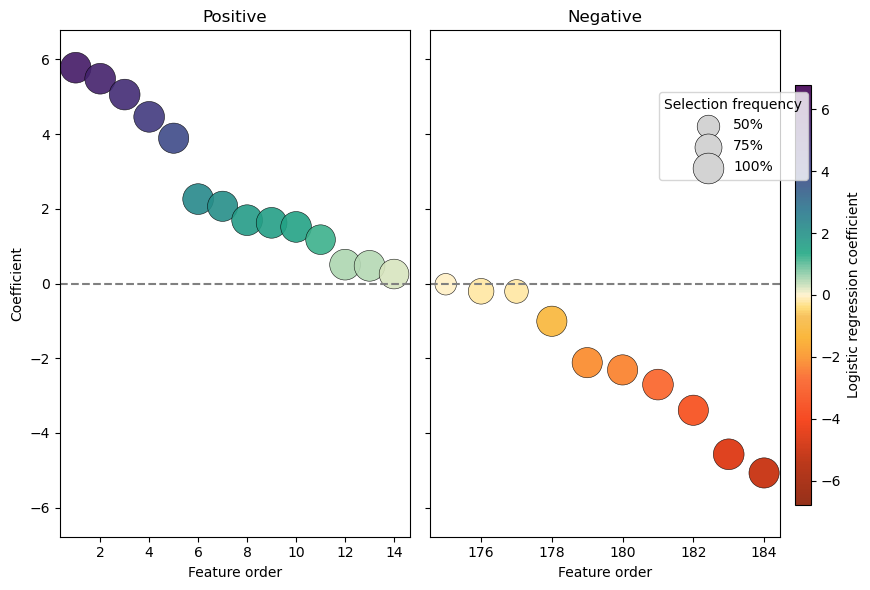

In [14]:
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

y_max = abs(plot_freq['coef']).max() + 1

norm = TwoSlopeNorm(vmin=-y_max, vcenter=0, vmax=y_max)

cmap_custom = LinearSegmentedColormap.from_list(
    "purple_zero_yellow_red_neg",
    [
        (0.00, "#8a1a01"), # Lowest
        (0.10, "#b52302"),
        (0.20, "#f5350a"),
        (0.30, "#fa6328"),
        (0.35, "#fa9128"),
        (0.40, "#fab028"),
        (0.45, "#f7bc4d"),
        (0.47, "#ffdb70"),
        (0.50, "#fff2cc"), # zero
        (0.60, "#22A884"),
        (0.70, "#2A788E"),
        (0.80, "#414487"),
        (1.00, "#440154"),
    ],
    N=256,
)

df_pos = plot_freq[plot_freq['coef'] > 0]
df_neg = plot_freq[plot_freq['coef'] < 0]

fig, axes = plt.subplots(1, 2, figsize=(8, 6), sharey=True)
fig.subplots_adjust(right=5)

axes[0].scatter(
    df_pos['order'],
    df_pos['coef'],
    s=40 + 450 * df_pos['sel_freq'],
    edgecolor="black",
    linewidth=0.4,
    alpha=0.9,
    c=df_pos["coef"],
    norm=norm,
    cmap=cmap_custom
)

axes[0].axhline(0, color='gray', linestyle='--')
axes[0].set_xlabel("Feature order")
axes[0].set_ylabel("Coefficient")
axes[0].set_title("Positive")
axes[0].set_ylim(-y_max, y_max)

sc= axes[1].scatter(
    df_neg['order'],
    df_neg['coef'],
    s=40 + 450 * df_neg['sel_freq'],
    edgecolor="black",
    linewidth=0.4,
    alpha=0.9,
    c=df_neg["coef"],
    norm=norm,
    cmap=cmap_custom
)

axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_xlabel("Feature order")
axes[1].set_title("Negative")
axes[1].set_ylim(-y_max, y_max)

cax = fig.add_axes([1, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
cbar = fig.colorbar(sc, cax=cax)
cbar.set_label("Logistic regression coefficient")

size_levels = [0.50, 0.75, 1.00]
handles = [
    plt.scatter([], [], s=40 + 450*s, facecolor="lightgray", edgecolor="black", linewidth=0.4)
    for s in size_levels
]
labels = [f"{int(s*100)}%" for s in size_levels]

plt.legend(
    handles, labels,
    title="Selection frequency",
    loc="upper right",
    bbox_to_anchor=(1.25, 1.0),
    frameon=True
)

plt.tight_layout()
# plt.savefig("Figures/Fig2a.pdf")
plt.show()


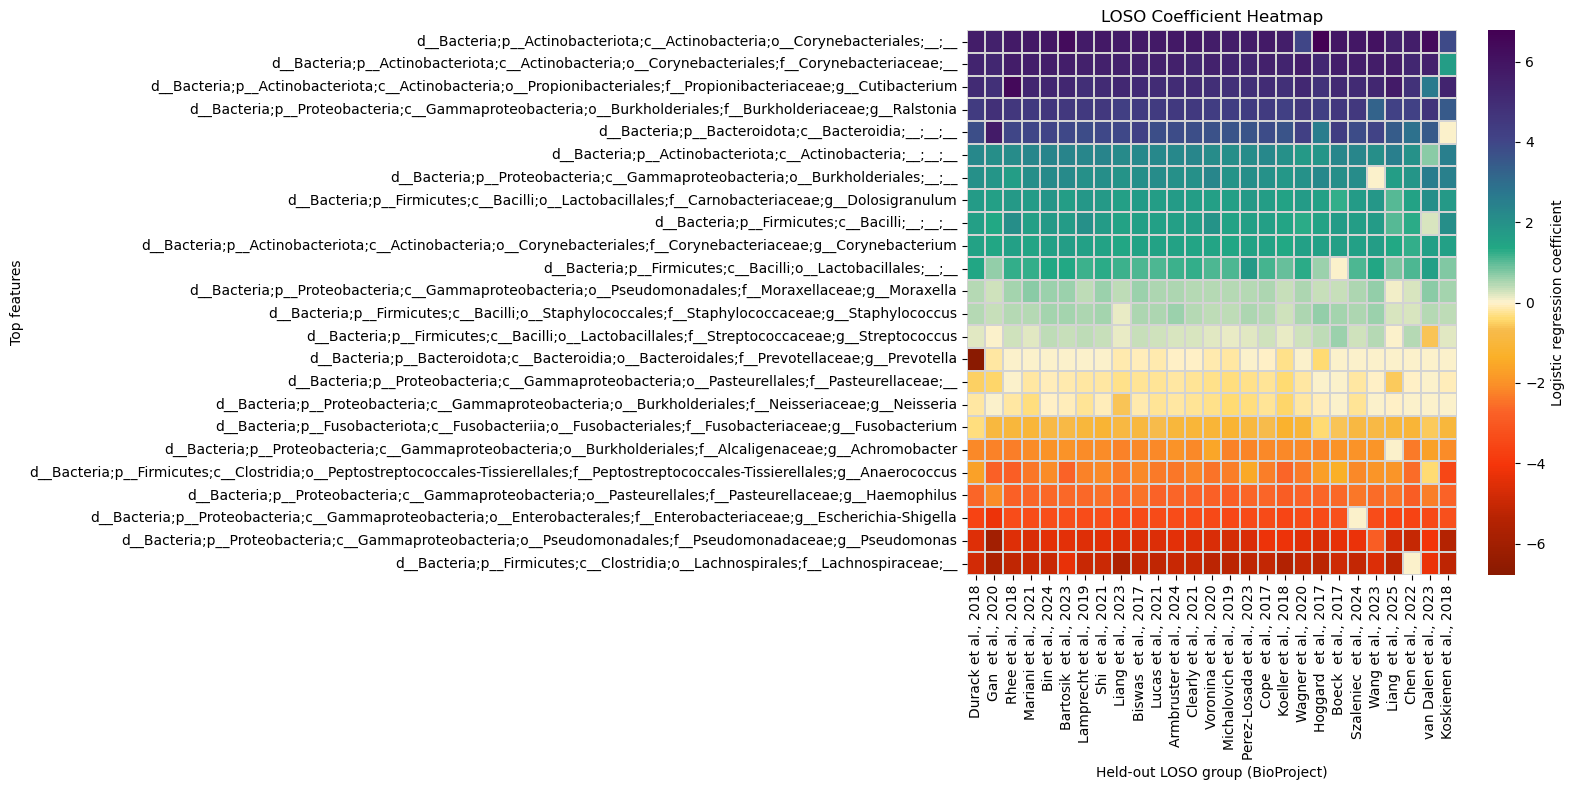

In [15]:
proj_to_citation = dict(
    zip(df['BioProject Number'],
        df['Citation'])
)

# Heatmap
pos_feats = df_pos.index.to_list()
neg_feats = df_neg.index.to_list()
feature_order = list(dict.fromkeys(pos_feats + neg_feats))
heat = coef_df[feature_order].T

# Order studies by total absolute coefficient magnitude
group_order = coef_df[feature_order].abs().sum(axis=1).sort_values(ascending=False).index
heat = heat[group_order]

# # rename columns
heat = heat.rename(columns=proj_to_citation)

fig_h = max(8, int(0.28 * heat.shape[0]))
fig_w = max(12, int(0.6 * heat.shape[1]))


plt.figure(figsize=(fig_w, fig_h))
sns.heatmap(
    heat,
    cmap=cmap_custom,
    norm = norm,
    linewidths=0.05,
    linecolor="lightgray",
    cbar_kws={"label": "Logistic regression coefficient"},
)

plt.xlabel("Held-out LOSO group (BioProject)")
plt.ylabel("Top features")
plt.title("LOSO Coefficient Heatmap")
plt.tight_layout()
# plt.savefig("Figures/Fig2b.pdf")
plt.show()

---